# 06 Tuning

tunes xgboost and lightgbm with a random search and checks whether tuning beats the default settings. each model gets 25 random tries plus the default as trial 0, using the same seed. a try is scored by pooled WAPE over the first 10 cutoffs only. the winner is then run on all 25 cutoffs, and judged mainly on the last 15, which the search never saw.

## Set-Up

In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from functools import partial

import sys
sys.path.append('../src')

from load_clean_data import load_clean_data
from backtest import get_cutoffs, run_backtest
from features import build_features
from evaluation import score_forecasts, merge_backtests
from models import add_lgbm_forecast, LGBM_PARAMS, add_xgb_forecast, XGB_PARAMS
from tuning import random_search

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [46]:
df = load_clean_data()
df_with_features = build_features(df)

In [47]:
cutoffs = get_cutoffs(df['Date'].max(), 7)
first_10 = cutoffs[:10]

## Search Spaces

what is searched and how. learning rate and regularisation use a log scale. lightgbm has subsample_freq fixed at 1, because otherwise subsample does nothing.

In [48]:
XGB_SEARCH_SPACE = {'max_depth': ('int', 2, 10),
                    'learning_rate': ('log', 0.01, 0.3),
                    'n_estimators': ('int', 100, 600),
                    'min_child_weight': ('int', 1, 50),
                    'subsample': ('float', 0.5, 1.0),
                    'colsample_bytree': ('float', 0.5, 1.0),
                    'reg_lambda': ('log', 0.1, 10)
                    }

LGBM_SEARCH_SPACE = {'num_leaves': ('int', 4, 127),
                     'learning_rate': ('log', 0.01, 0.3),
                     'n_estimators': ('int', 100, 600),
                     'min_child_samples': ('int', 10, 200),
                     'subsample': ('float', 0.5, 1.0),
                     'colsample_bytree': ('float', 0.5, 1.0),
                     'reg_lambda': ('log', 0.1, 10)
                    }

## XGBoost Search

In [49]:
RUN_XGB_SEARCH = False

In [50]:
if RUN_XGB_SEARCH:
    xgb_tuning = random_search(df_with_features, first_10, add_xgb_forecast, 'xgb_forecast', XGB_PARAMS, XGB_SEARCH_SPACE, n_trials=25, path='../results/tuning/xgb_tuning.csv')

    print(xgb_tuning.head(5))

else:
    xgb_tuning = pd.read_csv('../results/tuning/xgb_tuning.csv')

    print(xgb_tuning.head(5))

   trial  max_depth  learning_rate  n_estimators  min_child_weight  subsample  \
0     11          4       0.047629           491              26.0   0.569898   
1     15          5       0.066497           431              26.0   0.832157   
2     10          5       0.019737           503               1.0   0.893462   
3     17          8       0.054967           180              47.0   0.848160   
4      4          9       0.012424           530              42.0   0.815832   

   colsample_bytree  reg_lambda         RMSE         MAE       WAPE  \
0          0.557265    2.171730  1037.676514  600.600098  10.396508   
1          0.703193    4.246594  1046.446045  603.257812  10.442514   
2          0.832425    2.572354  1040.912842  604.042297  10.456093   
3          0.723078    0.578153  1053.123291  606.449585  10.497764   
4          0.879044    0.511743  1054.557495  608.962952  10.541272   

      seconds  
0  130.736621  
1  120.236105  
2  147.615089  
3   85.254588  
4  227

finding: the best try (trial 11) scores 10.40% against 10.61% for the default on the first 10 cutoffs. 7 of 25 tries beat the default, and the top 5 are all within 0.15 points. NaN in the table means the setting was not in the default params, so the library default was used. the search took about 53 minutes.

## LightGBM Search

In [51]:
RUN_LGBM_SEARCH = False

In [52]:
if RUN_LGBM_SEARCH:
    lgbm_tuning = random_search(df_with_features, first_10, add_lgbm_forecast, 'lgbm_forecast', LGBM_PARAMS, LGBM_SEARCH_SPACE, n_trials=25, path='../results/tuning/lgbm_tuning.csv')

    print(lgbm_tuning.head(5))

else:
    lgbm_tuning = pd.read_csv('../results/tuning/lgbm_tuning.csv')

    print(lgbm_tuning.head(5))

   trial  num_leaves  learning_rate  n_estimators  min_child_samples  \
0     11          38       0.047629           491              106.0   
1     24          55       0.016349           439               29.0   
2      1          15       0.044491           487               92.0   
3     18          22       0.027885           442              130.0   
4     17          92       0.054967           180              189.0   

   subsample  colsample_bytree  reg_lambda         RMSE         MAE  \
0   0.569898          0.557265    2.171730  1041.569247  594.547667   
1   0.793822          0.585296    7.083375  1046.619979  601.214989   
2   0.848684          0.547089    8.938090  1046.770635  601.831498   
3   0.680906          0.543825    0.172192  1053.008182  603.261592   
4   0.848160          0.723078    0.578153  1055.978529  606.623891   

        WAPE    seconds  
0  10.291740  50.417771  
1  10.407152  62.228377  
2  10.417824  50.147137  
3  10.442579  48.768198  
4  10.5007

finding: the best try (trial 11) scores 10.29% against 10.70% for the default. 16 of 25 tries beat the default. both searches used seed 42, so shared settings (learning rate, trees, subsample, colsample, lambda) got the same draws, and trial 11 was the best in both. a try took about 45 seconds against about 130 for xgboost.

## Tuned Parameters

the best row by WAPE from each search (trial 11 in both) is used. this rule was fixed before looking at the last 15 weeks.

In [53]:
XGB_TUNED_PARAMS = {
    'tree_method': 'hist',
    'enable_categorical': True,
    'n_estimators': 491,
    'learning_rate': 0.04762930519509523,
    'max_depth': 4,
    'min_child_weight': 26,
    'subsample': 0.5698984990638287,
    'colsample_bytree': 0.5572650367679868,
    'reg_lambda': 2.171730464570453,
    'random_state': 42
}

LGBM_TUNED_PARAMS = {
    'n_estimators': 491,
    'learning_rate': 0.04762930519509523,
    'num_leaves': 38,
    'subsample_freq': 1,
    'min_child_samples': 106,
    'subsample': 0.5698984990638287,
    'colsample_bytree': 0.5572650367679868,
    'reg_lambda': 2.171730464570453,
    'random_state': 42,
    'verbose': -1
}

## Tuned Backtests

both tuned models are run over all 25 cutoffs and saved with the other backtests.

In [ ]:
FORECAST = False

if FORECAST:
    add_tuned_xgb = partial(add_xgb_forecast, params=XGB_TUNED_PARAMS)

    bt = run_backtest(df_with_features, cutoffs, 7, add_tuned_xgb)

    xgb_tuned_bt = bt.rename(columns={'xgb_forecast': 'xgb_tuned_forecast'})

    xgb_tuned_bt = xgb_tuned_bt[['Store', 'Date', 'Sales', 'cutoff', 'day_ahead', 'xgb_tuned_forecast']]

    xgb_tuned_bt.to_csv('../results/backtests/xgb_tuned_backtest.csv', index=False)

else: 
    xgb_tuned_bt = pd.read_csv('../results/backtests/xgb_tuned_backtest.csv', parse_dates=['Date', 'cutoff'], low_memory=False)

In [55]:
SAVE_SCORES = True

if SAVE_SCORES:
    scores = score_forecasts(xgb_tuned_bt, ['xgb_tuned_forecast'])
    scores.to_csv('../results/xgb_tuned_scores.csv', index=False)

In [ ]:
FORECAST = False

if FORECAST:
    add_tuned_lgbm = partial(add_lgbm_forecast, params=LGBM_TUNED_PARAMS)

    bt = run_backtest(df_with_features, cutoffs, 7, add_tuned_lgbm)

    lgbm_tuned_bt = bt.rename(columns={'lgbm_forecast': 'lgbm_tuned_forecast'})

    lgbm_tuned_bt = lgbm_tuned_bt[['Store', 'Date', 'Sales', 'cutoff', 'day_ahead', 'lgbm_tuned_forecast']]

    lgbm_tuned_bt.to_csv('../results/backtests/lgbm_tuned_backtest.csv', index=False)

else: 
    lgbm_tuned_bt = pd.read_csv('../results/backtests/lgbm_tuned_backtest.csv', parse_dates=['Date', 'cutoff'], low_memory=False)

In [57]:
SAVE_SCORES = True

if SAVE_SCORES:
    scores = score_forecasts(lgbm_tuned_bt, ['lgbm_tuned_forecast'])
    scores.to_csv('../results/lgbm_tuned_scores.csv', index=False)

## Comparison
### All 25 Weeks

In [61]:
combined_bt = merge_backtests(['baselines', 'xgb', 'lgbm', 'xgb_tuned', 'lgbm_tuned'])

forecasts = ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgb_forecast', 'xgb_tuned_forecast', 'lgbm_forecast', 'lgbm_tuned_forecast']

combined_scores = score_forecasts(combined_bt, forecasts)

model_names = {
    'naive_baseline': 'Naive Baseline',
    'avg_28d_baseline': '28-Day Average Baseline',
    'avg_all_baseline': 'Full History Average Baseline',
    'xgb_forecast': 'XGBoost Forecast',
    'xgb_tuned_forecast': 'XGBoost Tuned',
    'lgbm_forecast': 'LightGBM Forecast',
    'lgbm_tuned_forecast': 'LightGBM Tuned'
}

relabelled_scores = combined_scores.copy()

relabelled_scores['Model'] = relabelled_scores['Model'].replace(model_names)

relabelled_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
LightGBM Tuned,994.37,597.28,10.19%
XGBoost Forecast,1001.30,604.95,10.33%
XGBoost Tuned,992.88,605.63,10.34%
LightGBM Forecast,1035.76,619.47,10.57%
Full History Average Baseline,2029.48,1261.49,21.53%
28-Day Average Baseline,2127.55,1326.10,22.63%
Naive Baseline,3206.68,2112.59,36.06%


finding: all four boosted models are between 10.2% and 10.6%, against 21.5% for the best baseline. tuning moves the scores by less than half a point.

### Held-Out Weeks (Last 15)

In [62]:
last_15_bt = combined_bt[~combined_bt['cutoff'].isin(first_10)]

assert last_15_bt['cutoff'].nunique() == 15, 'not 15 cutoffs'
assert len(last_15_bt) == 117075, 'wrong length'

last_15_scores = score_forecasts(last_15_bt, forecasts)

relabelled_scores = last_15_scores.copy()

relabelled_scores['Model'] = relabelled_scores['Model'].replace(model_names)

relabelled_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
LightGBM Tuned,949.23,593.35,10.03%
XGBoost Forecast,956.45,599.60,10.14%
XGBoost Tuned,961.86,608.98,10.30%
LightGBM Forecast,1011.97,620.17,10.49%
Full History Average Baseline,2019.27,1278.61,21.62%
28-Day Average Baseline,2151.14,1368.45,23.14%
Naive Baseline,3312.36,2170.45,36.70%


finding: the four boosted models score between 10.0% and 10.5% WAPE, against 21.6% for the best baseline, so they still have about half the error. tuned lightgbm is lowest (10.01%), then xgboost (10.14%), tuned xgboost (10.25%) and lightgbm (10.49%). the gaps between them are small, and the checks below show where they come from.

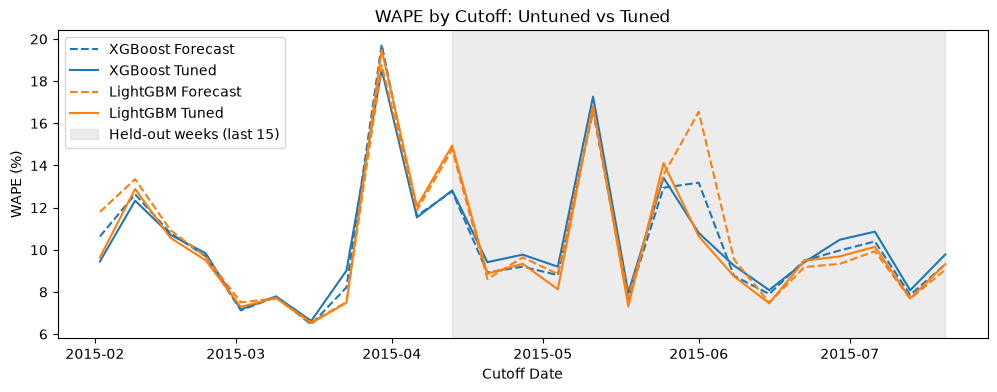

In [63]:
boosted = ['xgb_forecast', 'xgb_tuned_forecast', 'lgbm_forecast', 'lgbm_tuned_forecast']

scores_by_cutoff = score_forecasts(combined_bt, boosted, by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

styles = {
    'xgb_forecast': ('tab:blue', '--'),
    'xgb_tuned_forecast': ('tab:blue', '-'),
    'lgbm_forecast': ('tab:orange', '--'),
    'lgbm_tuned_forecast': ('tab:orange', '-'),
}

plt.figure(figsize=(12, 4))

for model in boosted:
    colour, line = styles[model]
    plt.plot(pivotted.index, pivotted[model], label=model_names[model], color=colour, linestyle=line)

plt.axvspan(cutoffs[10], cutoffs[-1], color='grey', alpha=0.15, label='Held-out weeks (last 15)')

plt.title('WAPE by Cutoff: Untuned vs Tuned')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

finding: the tuned lines are mostly below the untuned ones in the first 10 weeks, which are the weeks the search used. in the held-out weeks they mostly overlap, apart from the start of june. all four models are worst in the same weeks (end of march, mid may, start of june).

In [64]:
held_out = pivotted[~pivotted.index.isin(first_10)]

xgb_gain = held_out['xgb_forecast'] - held_out['xgb_tuned_forecast']
lgbm_gain = held_out['lgbm_forecast'] - held_out['lgbm_tuned_forecast']

print('xgboost: tuned better in', (xgb_gain > 0).sum(), 'of', len(xgb_gain), 'weeks')
print('lightgbm: tuned better in', (lgbm_gain > 0).sum(), 'of', len(lgbm_gain), 'weeks')

print(xgb_gain.sort_values(ascending=False).head(3))
print(lgbm_gain.sort_values(ascending=False).head(3))

xgboost: tuned better in 2 of 15 weeks
lightgbm: tuned better in 6 of 15 weeks
cutoff
2015-06-01    2.384969
2015-06-22    0.081988
2015-04-13   -0.050041
dtype: float64
cutoff
2015-06-01    5.904000
2015-06-08    0.805240
2015-05-04    0.728489
dtype: float64


finding: tuned xgboost is better in only 2 of 15 held-out weeks and tuned lightgbm in 6 of 15. both biggest gains are in the week of 1 jun (2.4 points for xgboost, 5.9 for lightgbm).

In [65]:
without_june = last_15_bt[last_15_bt['cutoff'] != '2015-06-01']

assert without_june['cutoff'].nunique() == 14, 'not 14 cutoffs'
assert len(without_june) == 14 * 7805, 'wrong length'

without_june_scores = score_forecasts(without_june, boosted)

without_june_scores['Model'] = without_june_scores['Model'].replace(model_names)

without_june_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
XGBoost Forecast,907.23,580.41,9.90%
LightGBM Tuned,923.67,585.69,9.99%
LightGBM Forecast,914.11,586.65,10.00%
XGBoost Tuned,937.24,601.68,10.26%


finding: most of lightgbm’s gain from tuning comes from one week. in the week of 1 jun, tuned lightgbm improves by 5.9 points over the untuned model. without that week, tuned and untuned lightgbm are level (9.99% against 10.00%), and tuned xgboost is worse than the default (10.26% against 9.90%).

finding: so tuning did not reliably improve either model on weeks the search never saw. the search found settings that handle the 1 jun week better, but none that beat the defaults elsewhere. the defaults were already close to as good as the search could find.

caveat: dropping the 1 jun week was chosen after seeing the results, so this shows where the gain came from and is not a cleaner score. the 15 week table is still the headline. it is also one search of 25 tries per model with one seed, so a different seed could pick different settings. i have not checked why the tuned models handle the 1 jun week better (it contains 4 jun, a holiday in some states).

## Summary

finding: random search over 25 tries on the first 10 weeks did not reliably beat the default settings for either model. on the 15 held out weeks, tuned xgboost is slightly worse than the default (10.25% against 10.14%) and tuned lightgbm is better (10.01% against 10.49%), but nearly all of lightgbm’s gain comes from one week (1 jun).

finding: all four boosted models still score between 10.0% and 10.5% on those weeks, about half the error of the best baseline (21.6%). a lightgbm try cost about a third of an xgboost one (about 45 seconds against about 130), so lightgbm is the cheaper choice for similar accuracy.